# Fair access to workshop registration information
**One fictional cohort, one notebook, matching the clarified slides.**

There are exactly **12 eligible students** in the population we study. Six live in university housing: **resident students R1–R6**. Six live off campus and travel to class: **commuter students C1–C6**. Every node is a student. **Workshop staff are outside the graph and outside the count of twelve.**

The workshop has room for all twelve. Staff may personally brief up to two students initially. Those selected students act as messengers and may forward to other students through the ten recorded links. Choosing a messenger does not choose who is allowed to attend. All twelve remain eligible.

We measure **which students receive registration information by the deadline**. The total can be 2, 8, 11 or another count depending on the plan, links and deadline. It is not a quota of workshop participants. Registrations, attendance and learning outcomes require separate data. Twelve informed would be the ideal information outcome, but the fixed outreach constraints can prevent it.

All students, housing categories, links and results are synthetic teaching data. These links do not claim that commuters generally have fewer friends. No external download or API key is required.

**Part 1** gives guided theory and runnable examples. **Part 2** gives final-project questions, hints and TODOs. Run Part 1 in order.

## Roles, links and success

| Item | Meaning |
|---|---|
| R2 | Resident student 2. A student, whether chosen as messenger or reached later. |
| C1 | Commuter student 1. Also eligible to become a messenger. |
| Staff | Organizers who choose the initial briefings. They are not student nodes. |
| R2 to C1 | R2 can forward the announcement to C1 in the next round. This is a directed forwarding opportunity, not a claim of reciprocal friendship. |
| 12 | The fixed number of eligible students whose information access we evaluate. |
| 2 | The limit on initial staff briefings in the main comparison. |
| 8 informed | An example result: eight unique students have the information, including messengers. This does not tell us how many attend. |

For a fixed budget and deadline, compare how many students are informed and each housing group's coverage. The later 20 pp rule is an explicit classroom choice. A gap alone cannot tell us whether enough people hear. The two-briefing limit defines this peer-outreach exercise; another communication channel would need its own cost and timing assumptions.

## Part 1. Guided theory and practice
### 1. Learning goals and data dictionary
After this notebook you should be able to trace forwarding by round, calculate group coverage and a gap in percentage points, compare strategies under a budget and deadline, and state what the measurements leave out.

| File | Rows | Fields and meaning |
|---|---:|---|
| `data/raw/people.csv` | 12 | `person`: unique fictional ID. `group`: Resident or Commuter, six students each. |
| `data/raw/links.csv` | 10 | `source`, `target`: directed forwarding opportunity. `p`: success probability, initially 1. |
| `data/raw/node_positions.json` | 12 positions | Teaching layout shared with the slides. These coordinates carry no behavioral information. |

There are no hiring features, suitability labels or trained classifier in this case. The derived individual outcome is `reached = 1` if first arrival occurs by the chosen deadline. The aggregate targets are total reach and group coverage. Group attributes support an audit, and do not determine whether a student deserves information.

In [1]:
from pathlib import Path
import sys, json, random, math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT / 'data/raw/people.csv').exists():
    raise FileNotFoundError('Unzip the complete package and open this notebook from its notebooks folder.')
sys.path.insert(0, str(ROOT / 'src'))
from network_lab import load_data, cascade, trace, metrics, evaluate_pairs, greedy_reach
people, links = load_data(ROOT)
positions = json.loads((ROOT / 'data/raw/node_positions.json').read_text())
display(people, links)
print(f'{len(people)} people, {len(links)} directed links')

12 people, 10 directed links


,person,group
0,R1,Resident
1,R2,Resident
2,R3,Resident
3,R4,Resident
4,R5,Resident
5,R6,Resident
6,C1,Commuter
7,C2,Commuter
8,C3,Commuter
9,C4,Commuter


,source,target,p
0,R1,R3,1.0
1,R1,R4,1.0
2,R1,R5,1.0
3,R2,R5,1.0
4,R2,R6,1.0
5,R2,C1,1.0
6,R2,C2,1.0
7,C1,C3,1.0
8,C1,C4,1.0
9,C1,C5,1.0


### 2. Data engineering checks
Before calculating fairness, check the denominator. Each person must appear once. Every link endpoint must be a known person. Duplicate links would give a person extra attempts in an incorrect simulator. A missing group would silently change a group denominator.

**Check by hand:** identify the two links that carry information from resident students to commuter students. Identify the person with no incoming or outgoing links. The answers are R2 to C1, R2 to C2, and C6. Isolation in this recorded graph does not establish isolation in real life.

In [2]:
assert len(people) == 12 and len(links) == 10
assert people.groupby('group').size().to_dict() == {'Resident': 6, 'Commuter': 6}
assert not people.isna().any().any()
in_degree = links.target.value_counts().reindex(people.person, fill_value=0)
out_degree = links.source.value_counts().reindex(people.person, fill_value=0)
degree = pd.DataFrame({'incoming': in_degree, 'outgoing': out_degree})
display(degree)
display(degree.loc[(degree.incoming == 0) & (degree.outgoing == 0)])

,incoming,outgoing
person,,
R1,0,3
R2,0,4
R3,1,0
R4,1,0
R5,2,0
R6,1,0
C1,1,3
C2,1,0
C3,1,0


,incoming,outgoing
person,,
C6,0,0


### 3. A figure with one meaning per visual feature
The ID prefix and outline identify the group. Lime fill identifies a direct contact. Pale blue fill identifies another recipient. White identifies someone unreached by the deadline. An arrow permits forwarding only in its direction.

The drawing function preserves node positions when the seed set or deadline changes. That lets you compare policies without mentally reconstructing the network.

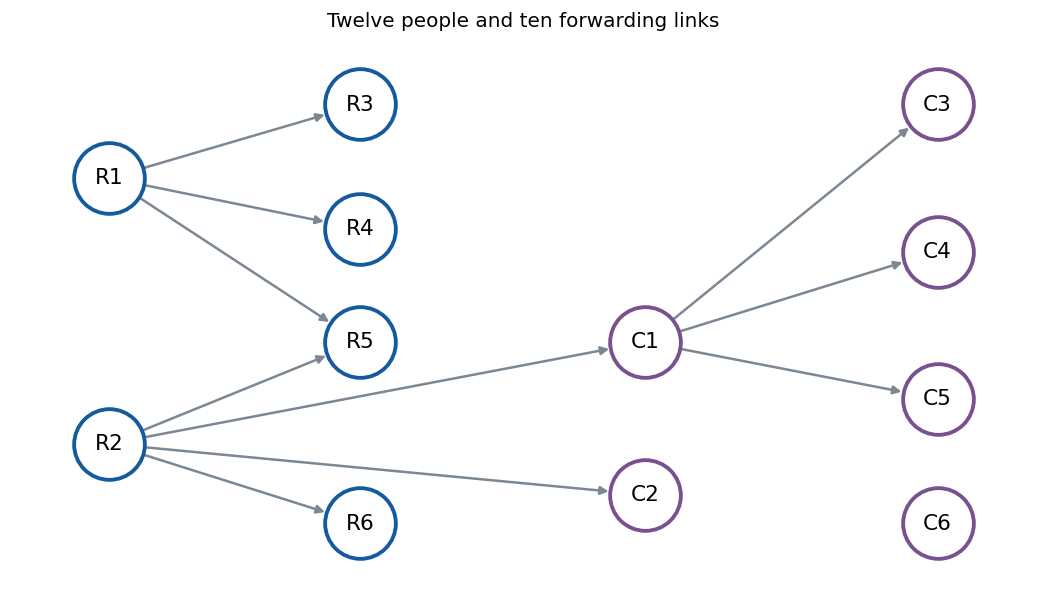

In [3]:
def draw_network(arrivals=None, seeds=(), title='Twelve people and ten forwarding links'):
    reached = set() if arrivals is None else set(arrivals.loc[arrivals.reached, 'person'])
    fig, ax = plt.subplots(figsize=(11, 6))
    for row in links.itertuples(index=False):
        x1,y1=positions[row.source]; x2,y2=positions[row.target]
        ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                    arrowprops=dict(arrowstyle='-|>', color='#7C8794', lw=1.5, shrinkA=22, shrinkB=22))
    for row in people.itertuples(index=False):
        x,y=positions[row.person]
        fill='#D2DE1A' if row.person in seeds else '#D9EAFB' if row.person in reached else 'white'
        edge='#165A9E' if row.group=='Resident' else '#775190'
        ax.scatter(x,y,s=1800,c=fill,edgecolors=edge,linewidths=2.3,zorder=3)
        ax.text(x,y,row.person,ha='center',va='center',fontsize=13,zorder=4)
    ax.set(xlim=(80,815),ylim=(650,160),title=title)
    ax.axis('off')
    plt.show()

draw_network()

### 4. Forwarding rules before equations
At round 0, direct contacts already have the message and count as recipients. Only newly informed people forward in the next round. Each outgoing link gets one chance. Count each person once even if two people contact them. Stop at the deadline. We first use `p=1`, so every attempted forwarding succeeds.

The simulator samples an independent success/failure value for each link before tracing paths. This is equivalent to the Independent Cascade model's one-attempt rule. It is a model assumption, not a claim that actual students act independently.

,round,new,cumulative,count
0,0,"R1, R2","R1, R2",2
1,1,"R3, R4, R5, R6, C1, C2","R1, R2, R3, R4, R5, R6, C1, C2",8
2,2,"C3, C4, C5","R1, R2, R3, R4, R5, R6, C1, C2, C3, C4, C5",11


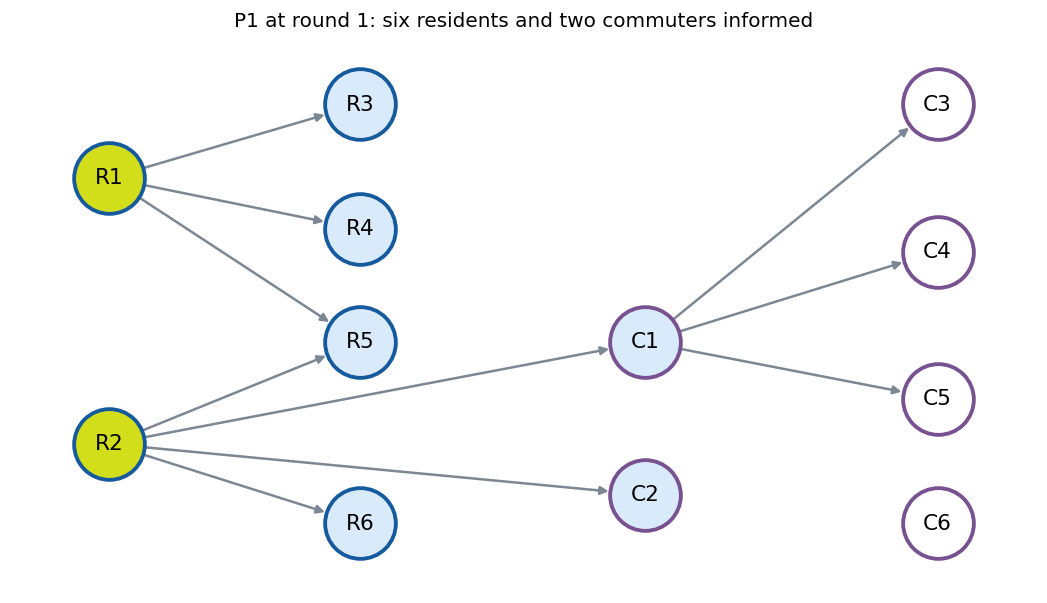

In [4]:
P1 = ['R1', 'R2']
arrivals_P1 = cascade(people, links, P1, deadline=2, p=1)
display(trace(arrivals_P1, 2))
draw_network(cascade(people, links, P1, deadline=1, p=1), P1, 'P1 at round 1: six residents and two commuters informed')

### 5. The first hand calculation
By round 1, R1 alone reaches `{R1,R3,R4,R5}`: four people. R2 alone reaches `{R2,R5,R6,C1,C2}`: five. Their overlap is R5: one person. Together they reach `4 + 5 - 1 = 8`, including both seeds.

Coverage means `reached in group / people in group`. Multiply by 100 to display a percentage. Residents have `6/6 = 100%`. Commuters have `2/6 = 33.333...%`. The absolute gap is `100 - 33.333... = 66.666... percentage points`. We keep full precision during calculations and round only for display.

In [5]:
a1 = cascade(people, links, ['R1'], 1, p=1)
a2 = cascade(people, links, ['R2'], 1, p=1)
r1 = set(a1.loc[a1.reached, 'person'])
r2 = set(a2.loc[a2.reached, 'person'])
print('R1 alone:', sorted(r1))
print('R2 alone:', sorted(r2))
print('Shared:', sorted(r1 & r2))
print(f'Union = {len(r1)} + {len(r2)} - {len(r1 & r2)} = {len(r1 | r2)}')
group_P1, result_P1 = metrics(cascade(people, links, P1, 1, p=1))
display(group_P1)
print(result_P1)

R1 alone: ['R1', 'R3', 'R4', 'R5']
R2 alone: ['C1', 'C2', 'R2', 'R5', 'R6']
Shared: ['R5']
Union = 4 + 5 - 1 = 8
{'total': 8, 'gap_pp': 66.66666666666667, 'min_coverage_pct': 33.33333333333333, 'sqrt_count_utility': 3.863703305156273}


,reached,size,coverage,coverage_pct
group,,,,
Resident,6,6,1.000000,100.000000
Commuter,2,6,0.333333,33.333333


### 6. A different seed set, the same total
P2 contacts R1 and C1. By round 1 it reaches R1,R3,R4,R5 and C1,C3,C4,C5. That is four people in each group, eight in total, coverage `4/6 = 66.666...%` for each group and a gap of zero.

**Your checkpoint before running:** P3 contacts R2 and C1. List its recipients and calculate the two fractions. It reaches R2,R5,R6 and C1,C2,C3,C4,C5, giving `3/6=50%`, `5/6=83.333...%`, total 8 and gap `33.333... pp`.

,policy,seeds,resident_pct,commuter_pct,total,gap_pp,min_coverage_pct,sqrt_count_utility
0,P1,"R1, R2",100.000,33.333,8,66.667,33.333,3.864
1,P2,"R1, C1",66.667,66.667,8,0.000,66.667,4.000
2,P3,"R2, C1",50.000,83.333,8,33.333,50.000,3.968


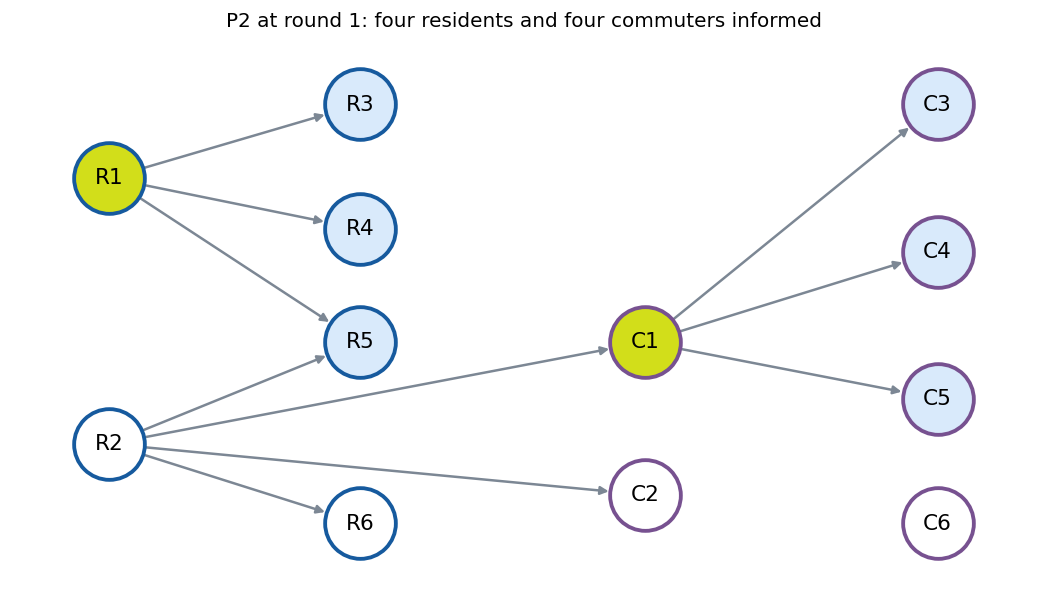

In [6]:
policies = {'P1': ['R1','R2'], 'P2': ['R1','C1'], 'P3': ['R2','C1']}
rows=[]
for name, seeds in policies.items():
    arrivals=cascade(people,links,seeds,1,p=1)
    group, result=metrics(arrivals)
    rows.append({'policy':name,'seeds':', '.join(seeds),
                 'resident_pct':group.loc['Resident','coverage_pct'],'commuter_pct':group.loc['Commuter','coverage_pct'],**result})
comparison=pd.DataFrame(rows)
display(comparison.round(3))
draw_network(cascade(people,links,policies['P2'],1,p=1), policies['P2'], 'P2 at round 1: four residents and four commuters informed')

### 7. A decision rule needs both benefit and a fairness measure
Consider this teaching policy: at most two direct contacts, and a coverage gap of at most 20 percentage points. Among feasible seed sets, maximize total reach.

The empty set has zero gap because nobody receives the message. That demonstrates why zero gap alone is insufficient. Maximize reach subject to the limit, or add an explicit minimum benefit requirement. The 20 pp tolerance is a chosen classroom policy, not a legal standard or an empirically established fairness threshold.

In [7]:
all_pairs=evaluate_pairs(people,links,deadline=1)
assert len(all_pairs)==math.comb(12,2)==66
feasible=all_pairs.loc[all_pairs.gap_pp <= 20 + 1e-9]
best=feasible.sort_values(['total','gap_pp','seeds'],ascending=[False,True,True])
display(best.head(8).round(3))
print('At round 1 the unique maximum-reach zero-gap pair is R1, C1.')

At round 1 the unique maximum-reach zero-gap pair is R1, C1.


,seeds,deadline,reached_residents,reached_commuters,total,gap_pp,min_coverage_pct,sqrt_count_utility
5,"R1, C1",1,4,4,8,0.000,66.667,4.000
17,"R2, C3",1,3,3,6,0.000,50.000,3.464
18,"R2, C4",1,3,3,6,0.000,50.000,3.464
19,"R2, C5",1,3,3,6,0.000,50.000,3.464
20,"R2, C6",1,3,3,6,0.000,50.000,3.464
16,"R2, C2",1,3,2,5,16.667,33.333,3.146
13,"R2, R5",1,3,2,5,16.667,33.333,3.146
14,"R2, R6",1,3,2,5,16.667,33.333,3.146


### 8. The deadline changes the comparison
At round 2, P1 adds C3,C4,C5 through C1. P1 then reaches six residents and five commuters informed, total 11, and gap `|6/6 - 5/6| × 100 = 16.666... pp`. P2 still reaches eight with a gap of zero. Under the 20 pp rule, P1 becomes feasible and has more total reach.

This conclusion applies to the specified deadline, topology, budget and forwarding model. It does not mean waiting longer is always acceptable, nor that every group's information arrives soon enough to benefit.

,deadline,policy,total,gap_pp,min_coverage_pct,sqrt_count_utility,passes_20pp
0,1,P1,8,66.667,33.333,3.864,False
1,1,P2,8,0.000,66.667,4.000,True
2,1,P3,8,33.333,50.000,3.968,False
3,2,P1,11,16.667,83.333,4.686,True
4,2,P2,8,0.000,66.667,4.000,True
5,2,P3,8,33.333,50.000,3.968,False


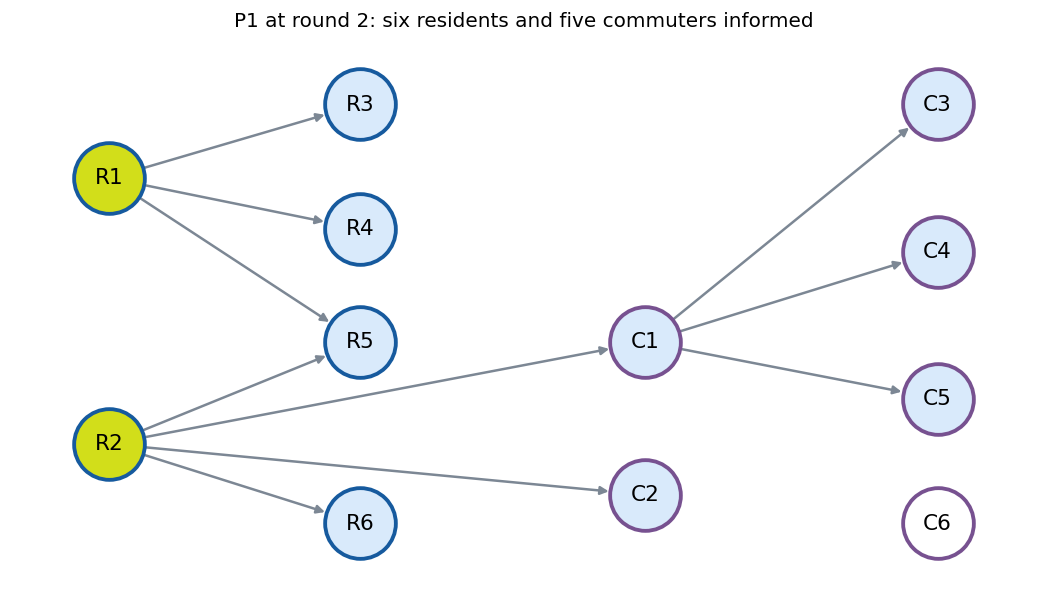

In [8]:
deadline_rows=[]
for deadline in [1,2]:
    for name,seeds in policies.items():
        a=cascade(people,links,seeds,deadline,p=1)
        g,m=metrics(a)
        deadline_rows.append({'deadline':deadline,'policy':name,**m,'passes_20pp':m['gap_pp'] <= 20+1e-9})
display(pd.DataFrame(deadline_rows).round(3))
draw_network(arrivals_P1,P1,'P1 at round 2: six residents and five commuters informed')

### 9. Optional extension: greedy means the largest next improvement
At round 1, the single seed R2 reaches five people, R1 four, C1 four, and each of the other nine people only themselves. Greedy total-reach selection therefore starts with R2. Adding R1 then adds three new people. Adding C1 also adds three. The implementation breaks this tie by the class-list row order and chooses R1.

The final greedy pair is P1. It maximizes total reach on this tiny example but misses the 20 pp constraint. Adding a fairness constraint to a problem does not automatically change a total-reach greedy algorithm. Evaluate the resulting gap explicitly.

In [9]:
selected, greedy_history=greedy_reach(people,links,budget=2,deadline=1)
display(greedy_history)
print('Selected:', selected)
display(all_pairs.loc[all_pairs.seeds.isin(['R1, R2','R2, C1','R1, C1'])].round(3))

Selected: ['R2', 'R1']


,step,selected_before,ties,choice,new_recipients
0,1,,R2,R2,5
1,2,R2,"R1, C1",R1,3


,seeds,deadline,reached_residents,reached_commuters,total,gap_pp,min_coverage_pct,sqrt_count_utility
0,"R1, R2",1,6,2,8,66.667,33.333,3.864
5,"R1, C1",1,4,4,8,0.000,66.667,4.000
15,"R2, C1",1,3,5,8,33.333,50.000,3.968


### 10. Optional extension: uncertain forwarding and expected reach
Use R2 as the **only seed**, deadline 2, and independent success probability 0.5 on every link. R2 contributes 1. Its four immediate neighbors each have probability 0.5. C3,C4,C5 each require R2 to reach C1 and C1 to forward, giving `0.5 × 0.5 = 0.25` each. The expected total is `1 + 4×0.5 + 3×0.25 = 3.75`.

Expected resident count is `1 + 2×0.5 = 2`. Expected commuter count is `2×0.5 + 3×0.25 = 1.75`. A single trial always has an integer count. The average of many trials can be fractional. Expected group coverage and expected realized gap are distinct statistics because absolute values do not generally commute with averages.

Simulated mean: 3.74
Analytical expectation: 3.75


,trial,reached_residents,reached_commuters,total,gap_pp,min_coverage_pct,sqrt_count_utility
0,1,2,0,2,33.333333,0.000000,1.414214
1,2,2,1,3,16.666667,16.666667,2.414214
2,3,2,3,5,16.666667,33.333333,3.146264
3,4,2,0,2,33.333333,0.000000,1.414214
4,5,3,4,7,16.666667,50.000000,3.732051
5,6,1,1,2,0.000000,16.666667,2.000000


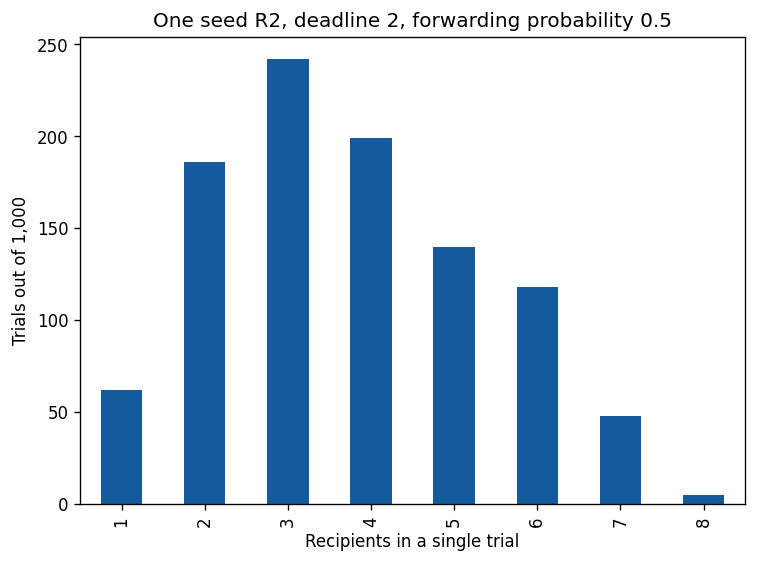

In [10]:
rng=random.Random(42)
trials=[]
for run in range(1,1001):
    a=cascade(people,links,['R2'],deadline=2,p=0.5,rng=rng)
    g,m=metrics(a)
    trials.append({'trial':run,'reached_residents':int(g.loc['Resident','reached']),
                   'reached_commuters':int(g.loc['Commuter','reached']),**m})
simulation=pd.DataFrame(trials)
display(simulation.head(6))
print('Simulated mean:', simulation.total.mean())
print('Analytical expectation:', 1 + 4*0.5 + 3*0.25)
simulation.total.value_counts().reindex(range(1,9),fill_value=0).sort_index().plot.bar(color='#165A9E')
plt.xlabel('Recipients in a single trial')
plt.ylabel('Trials out of 1,000')
plt.title('One seed R2, deadline 2, forwarding probability 0.5')
plt.tight_layout()
plt.show()

### 11. Ethical interpretation and a response
C6 has no links in the recorded network. The equal-coverage policy P2 never reaches C6. Group parity therefore does not establish universal access. R2 and C6 as direct contacts reaches three A and three B by round 1, total six, with zero gap, and includes C6. This involves an explicit tradeoff in total reach.

Possible responses include a direct reminder, accessible email, an in-person announcement or a non-network channel. Specify the cost and feasibility of an added channel before comparing policies. Ask whether links are missing, whether people consented to collection, whether a group field is justified, and whether receipt was actually observed. Do not infer protected identity from a name. An audit of receipt must not claim an audit of attendance or learning benefit.

{'total': 6, 'gap_pp': 0.0, 'min_coverage_pct': 50.0, 'sqrt_count_utility': 3.4641016151377544}


,reached,size,coverage,coverage_pct
group,,,,
Resident,3,6,0.5,50.0
Commuter,3,6,0.5,50.0


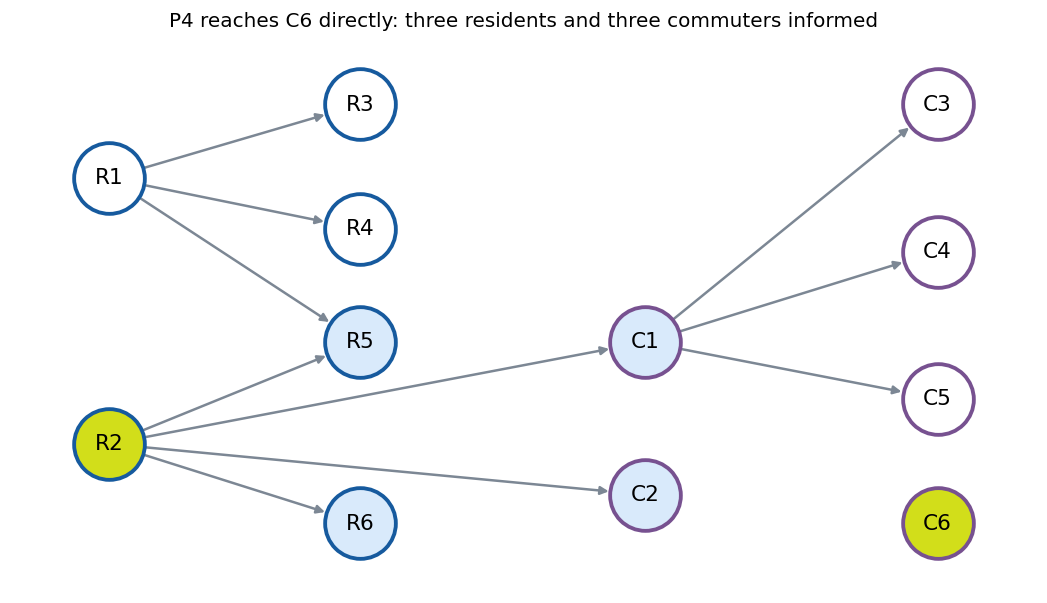

In [11]:
P4=['R2','C6']
g,m=metrics(cascade(people,links,P4,1,p=1))
display(g)
print(m)
draw_network(cascade(people,links,P4,1,p=1),P4,'P4 reaches C6 directly: three residents and three commuters informed')
OUT=ROOT/'data/processed'
OUT.mkdir(exist_ok=True)
comparison.to_csv(OUT/'student_policy_comparison.csv',index=False)
all_pairs.to_csv(OUT/'student_all_66_pairs.csv',index=False)
simulation.to_csv(OUT/'student_simulation_1000.csv',index=False)

### 12. What would it take to inform all twelve?

Keep deadline 2 and p=1. Briefing R1 and R2 informs 11 students: six residents and five commuters. C6 has no incoming link. A third initial briefing to C6 informs all twelve by round 2.

This is an explicit change from **two briefings to three**, not a solution satisfying the original budget. Under peer forwarding alone, R1, R2 and C6 each have no incoming link, so all three must be initially briefed for everyone to receive the message. All twelve informed still does not establish twelve registrations or attendees.

,briefings,initial_students,residents_informed,commuters_informed,total,gap_pp,min_coverage_pct,sqrt_count_utility
0,2,"R1, R2",6,5,11,16.667,83.333,4.686
1,3,"R1, R2, C6",6,6,12,0.000,100.000,4.899


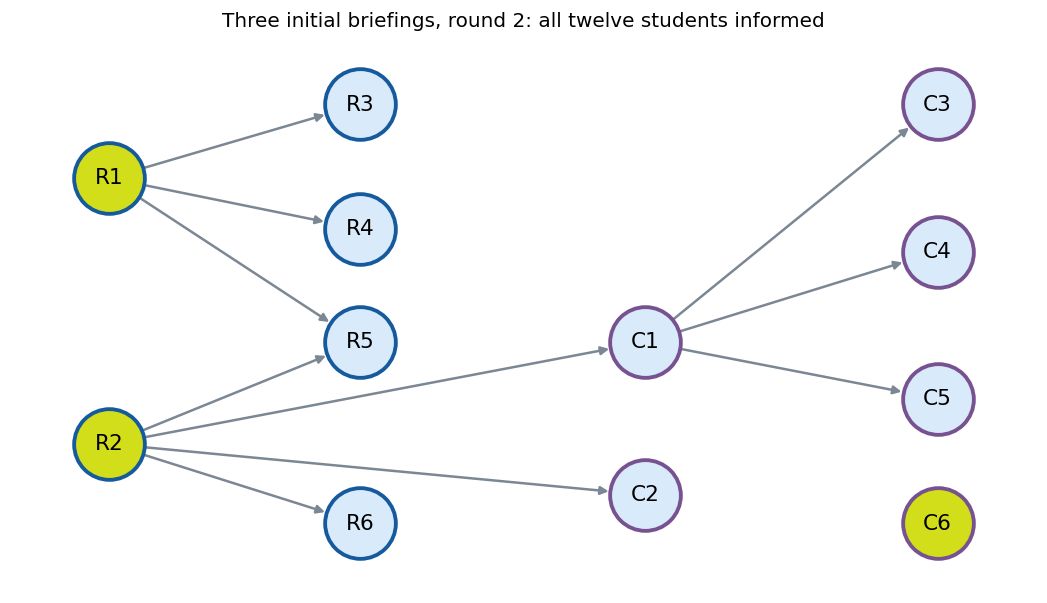

In [12]:
rows=[]
for seeds in [['R1','R2'],['R1','R2','C6']]:
    group, result=metrics(cascade(people,links,seeds,deadline=2,p=1))
    rows.append({'briefings':len(seeds),'initial_students':', '.join(seeds),
                 'residents_informed':int(group.loc['Resident','reached']),
                 'commuters_informed':int(group.loc['Commuter','reached']),**result})
display(pd.DataFrame(rows).round(3))
draw_network(cascade(people,links,['R1','R2','C6'],2,p=1),['R1','R2','C6'],
             'Three initial briefings, round 2: all twelve students informed')

### 13. Ethical interpretation and real-world transfer

The general problem is **how an institution allocates useful information that people need to access an opportunity or respond to a risk**. A network and a deadline influence who hears. An algorithm may optimize that distribution. People still have to justify the objective, the population definition and the treatment of people who miss out.

| Workshop component | General meaning | Examples |
|---|---|---|
| Twelve eligible students | People to whom the institution's outreach is relevant | Eligible scholarship applicants or people in a warning area |
| Announcement | Information needed before a decision or deadline | How to apply for support or respond to a hazard |
| Two initial briefings | A simplified outreach resource constraint | Staff time, paid messages or calls, with an explicit cost model |
| Forwarding graph | Recorded routes by which information may travel | Peer contacts, community messengers or organizational networks |
| Coverage and gap | Evidence about the distribution of information | Which groups and individuals receive timely information |

**Real-world transfer requires revisiting assumptions.** People may be absent from a recorded graph. A public warning can use broadcast channels. Receipt does not establish understanding or the ability to act. A two-contact constraint needs justification when an official notice to everyone eligible is feasible. The twelve-person percentages are teaching results and cannot be treated as real estimates.

#### 13.1 Who benefits from changing P1 to P2?

Compare the alternative plans before outreach begins. At round 1 and the same two-briefing budget, both plans would inform eight. The sets differ. List the people who gain, lose or remain uninformed before declaring one plan ethically preferable. Explain what each person could lose if this message concerned an opportunity for which they were eligible. Actual registration outcomes remain unknown.

In [13]:
p1_receipt=cascade(people,links,['R1','R2'],deadline=1,p=1)
p2_receipt=cascade(people,links,['R1','C1'],deadline=1,p=1)
changes=people.merge(p1_receipt[['person','reached']].rename(columns={'reached':'P1_informed'}),on='person',validate='one_to_one')
changes=changes.merge(p2_receipt[['person','reached']].rename(columns={'reached':'P2_informed'}),on='person',validate='one_to_one')
changes['change']='Informed under both'
changes.loc[~changes.P1_informed & changes.P2_informed,'change']='Gains under P2'
changes.loc[changes.P1_informed & ~changes.P2_informed,'change']='Loses under P2'
changes.loc[~changes.P1_informed & ~changes.P2_informed,'change']='Missed under both'
assert set(changes.loc[changes.change.eq('Gains under P2'),'person'])=={'C3','C4','C5'}
assert set(changes.loc[changes.change.eq('Loses under P2'),'person'])=={'R2','R6','C2'}
assert set(changes.loc[changes.change.eq('Missed under both'),'person'])=={'C6'}
display(changes)
changes.to_csv(OUT/'access_changes_P1_P2.csv',index=False)


,person,group,P1_informed,P2_informed,change
0,R1,Resident,True,True,Informed under both
1,R2,Resident,True,False,Loses under P2
2,R3,Resident,True,True,Informed under both
3,R4,Resident,True,True,Informed under both
4,R5,Resident,True,True,Informed under both
5,R6,Resident,True,False,Loses under P2
6,C1,Commuter,True,True,Informed under both
7,C2,Commuter,True,False,Loses under P2
8,C3,Commuter,False,True,Gains under P2
9,C4,Commuter,False,True,Gains under P2


#### 13.2 A principle and a defensible recommendation

One possible principle is **equal opportunity to hear about an opportunity for which people are eligible**. Under that principle, P2's balanced group coverage at the same total is a reason to prefer it. That choice changes who receives information. It leaves four students uninformed, including C6. A different priority, such as an especially urgent individual need, requires evidence about that need. Housing labels alone cannot establish it.

**Worked decision memo:** “P1 informs all six residents and two commuters by round 1. P2 informs four students in each group at the same total and budget. I prefer P2 under an equal-group-opportunity principle. The choice nevertheless removes R2, R6 and C2 from the informed set while adding C3, C4 and C5. C6 remains excluded. The organizer should assess an accessible official announcement and follow-up support for people it misses. That proposal changes the channel assumptions, so its cost and delivery checks must be stated. We still need evidence about whether people understand the next step and can use it. The counts do not establish actual missed registrations or legal discrimination.”

**Responsibility:** organizers control the outreach design and should justify it. A missing edge does not show that a student has no friends or lacks motivation. Respect a person's choice about whether to register or forward a message.

#### 13.3 Receipt and a usable next step are different outcomes

This extension first uses the known three-briefing plan `R1,R2,C6`, deadline 2, p=1, to inform all twelve. It then adds a **separate, explicitly fictional access check**. These are invented individual conditions, not observations or predictions about real resident or commuter students.

`data/raw/access_checks.csv` contains one row per student:

| Field | Type and meaning | Ethical caution |
|---|---|---|
| person | Existing R/C student ID | Join once, without changing the cohort denominator |
| understands_action | 0/1 teaching assumption about understanding the next step | A real audit needs an appropriate, voluntary way to learn this |
| can_use_next_step | 0/1 teaching assumption about using the next step | Ability to act depends on design and support, not a person's worth |
| barrier | Fictional cue for a remedy | Never infer it from the housing group |
| provenance | `fictional teaching assumption` | No real personal or disability data are included |

Assume R5 needs an alternate format, C3 needs clearer action instructions and C6 needs help with the form. The other nine pass these simplified checks. Define an exercise-specific indicator as timely receipt **and** understanding the action **and** ability to use the next step. This indicator is a classroom proxy. It does not certify accessibility or measure attendance, benefit entitlement or learning.

Timely receipt: 12/12, gap 0 pp.
Usable next step: residents 5/6, commuters 4/6; total 9/12, gap 16.67 pp.


,person,group,reached,understands_action,can_use_next_step,barrier,usable_next_step
0,R1,Resident,True,1,1,none,True
1,R2,Resident,True,1,1,none,True
2,R3,Resident,True,1,1,none,True
3,R4,Resident,True,1,1,none,True
4,R5,Resident,True,1,0,alternate_format,False
5,R6,Resident,True,1,1,none,True
6,C1,Commuter,True,1,1,none,True
7,C2,Commuter,True,1,1,none,True
8,C3,Commuter,True,0,1,unclear_action,False
9,C4,Commuter,True,1,1,none,True


,Received in time (%),Usable next step (%)
group,,
Resident,100.0,83.33
Commuter,100.0,66.67


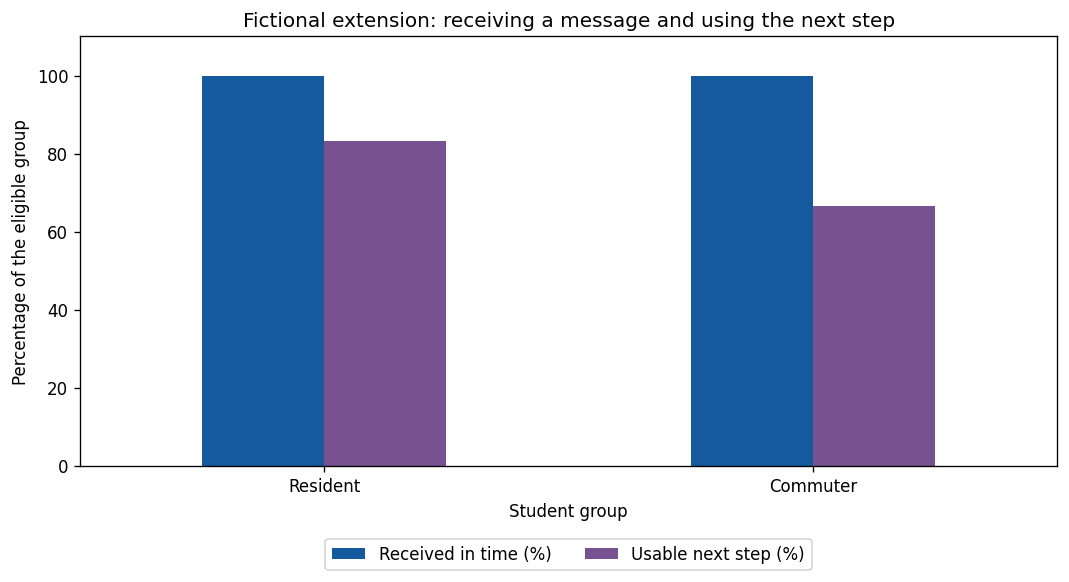

In [14]:
access=pd.read_csv(ROOT/'data/raw/access_checks.csv')
assert access.person.is_unique and set(access.person)==set(people.person)
assert not access.isna().any().any()
for column in ['understands_action','can_use_next_step']:
    assert access[column].isin([0,1]).all()
assert access.provenance.eq('fictional teaching assumption').all()
universal_receipt=cascade(people,links,['R1','R2','C6'],deadline=2,p=1)
checked=universal_receipt.merge(access,on='person',validate='one_to_one')
assert len(checked)==12 and checked.reached.all()
checked['usable_next_step']=(checked.reached & checked.understands_action.eq(1) & checked.can_use_next_step.eq(1))
receipt_groups,receipt_summary=metrics(checked)
usable_groups,usable_summary=metrics(checked.assign(reached=checked.usable_next_step))
assert receipt_summary['total']==12 and receipt_summary['gap_pp']==0
assert usable_summary['total']==9 and math.isclose(usable_summary['gap_pp'],100/6,abs_tol=1e-9)
audit=pd.DataFrame({'Received in time (%)':receipt_groups.coverage_pct,'Usable next step (%)':usable_groups.coverage_pct})
display(checked[['person','group','reached','understands_action','can_use_next_step','barrier','usable_next_step']])
display(audit.round(2))
print('Timely receipt: 12/12, gap 0 pp.')
print('Usable next step: residents 5/6, commuters 4/6; total 9/12, gap 16.67 pp.')
checked.to_csv(OUT/'fictional_access_audit.csv',index=False)
audit.to_csv(OUT/'receipt_and_usable_access.csv')
ax=audit.plot.bar(color=['#165A9E','#775190'],rot=0,ylim=(0,110),figsize=(9,5))
ax.set_ylabel('Percentage of the eligible group')
ax.set_xlabel('Student group')
ax.set_title('Fictional extension: receiving a message and using the next step')
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.15),ncol=2)
plt.tight_layout()
plt.show()


#### 13.4 What the access check means ethically

The receipt gap is zero, while three individuals still face a barrier. The practical issue is their ability to use an eligible opportunity. A lower gap at the receipt stage cannot answer that question. This extension also shows why a new outcome needs its own definition and data.

| Finding | Concern | Candidate remedy and owner | Evidence needed afterwards |
|---|---|---|---|
| R5 receives an unusable format | Accessibility | Organizer offers a suitable alternative format | R5 can use the next step, with an appropriate check |
| C3 cannot identify the action | Understandability | Organizer rewrites and tests the action instructions | The action and deadline are clear |
| C6 cannot use the form | Meaningful opportunity | Organizer provides application support | The form is usable without unnecessary dependence or data disclosure |
| A graph may omit eligible people | Recognition and denominator bias | Institution checks an independent population source | Eligible people outside the recorded graph are considered |
| An audit may reveal personal relationships or support needs | Privacy and agency | Audit owner limits fields and identifiable access | The audit can answer its question with proportionate data |

These remedies are proposals to test. Do not flip the flags to 1 and report success without evidence. Record new channel costs and delivery assumptions. Respect a person's choice to decline participation or assistance.

#### 13.5 Transfer to real settings

| Setting and status | Relevant message and population | Ethical problem | What must change in the toy model? |
|---|---|---|---|
| Scholarship announcement, illustrative scenario | Eligible applicants need application information | Missing the notice may remove a chance to apply | Verify eligibility, accessible official channels and the application deadline |
| Employer training, illustrative scenario | Eligible staff need a course announcement | Informal networks may restrict a career opportunity | Define the eligible staff population and separate receipt from final course selection |
| German public warnings, documented BBK system | People in an affected area need a timely warning | One unavailable or failed channel may leave a person exposed to harm | Include complementary broadcast routes, changing populations, accessibility and serious safety stakes |
| Access to public benefits, documented OECD problem | Potentially eligible people need usable information and application support | Information and application barriers can prevent access to support | Account for people outside records, uncertainty about eligibility and application obstacles |

BBK's warning-channel approach illustrates why an institution can change the communication design rather than accept a peer-only graph. OECD documents barriers beyond receiving information. Neither source validates the twelve-student network or its percentages.

#### 13.6 Classroom task and assessment

In pairs, replace the workshop with one opportunity in the table. Write **150 words** explaining your recommendation. Include one correctly calculated fraction and name an individual or group who may still miss out. State the ethical principle that guides your recommendation, a feasible remedy, the responsible organizer, its resource assumption and one evidence gap.

The teacher can assess five aspects, 0–2 points each: a concrete opportunity and affected people; a stated and defended principle; accurate use of the numerical evidence; a feasible remedy with an owner and cost; and an honest account of what remains unknown. A student can defend a different priority if the reasoning and consequences are consistent. Arithmetic alone does not complete the ethical analysis.

#### 13.7 Further reading and source status

- [BBK: So werden Sie gewarnt](https://www.bbk.bund.de/DE/Warnung-Vorsorge/Warnung-in-Deutschland/So-werden-Sie-gewarnt/so-werden-sie-gewarnt_node.html), explanation of Germany's complementary warning channels.
- [OECD (2024), Modernising Access to Social Protection](https://doi.org/10.1787/af31746d-en), especially chapters 1–2 on information and application barriers.
- [W3C, WCAG 2.2](https://www.w3.org/TR/WCAG22/), recommendations for accessible web content. The binary classroom flags do not constitute a conformance test.

Sources accessed 18 October 2026. The raw access-check table is new fictional teaching data. No real emergency, benefit or scholarship microdata are claimed or included.

## Part 2. Final-project extensions
Your project must state a decision, a data-generating process, an outcome and a fairness criterion. Choose one main extension. Change one assumption at a time before combining changes. Compare a baseline and at least one response. Retain raw data and save derived tables separately.

### TODO A. Budget and deadline sensitivity
**Question:** how do total reach and minimum group coverage change for budgets 1,2,3 and deadlines 0,1,2?

**Hints:** replace pair enumeration with `itertools.combinations(person_ids,budget)`. Do not compare a budget-three method with a budget-two baseline without explaining the cost difference. Plot both benefit and disparity. Count seeds at round 0.

**Deliverable:** a policy-by-budget-by-deadline table, one plot and a recommendation tied to a specific deadline.

In [15]:
def project_budget_deadline(people, links, budgets=(1,2,3), deadlines=(0,1,2)):
    # TODO: enumerate seed sets for each budget.
    # TODO: use cascade and metrics, then save one row per scenario.
    # TODO: state and implement how ties are resolved.
    raise NotImplementedError('Project extension: implement before calling')

### TODO B. Uncertain and incomplete links
**Question:** does the recommendation survive forwarding probabilities 0.2,0.5,0.8 or a missing bridge from R2 to C1?

**Hints:** repeat each policy many times using documented random seeds. Report group coverage uncertainty and the frequency that a realized gap exceeds your threshold. Distinguish a gap between mean group coverages from the mean of trial gaps. Simulate several missing-edge patterns. A link absent from a dataset can still exist in the world.

**Deliverable:** estimates with uncertainty, a sensitivity plot, and a paragraph explaining which conclusions depend on independence or missingness assumptions.

In [16]:
def project_uncertainty(people, links, seed_sets, repetitions=1000):
    # TODO: loop over probabilities, policies and random trials.
    # TODO: store group counts, not only the final gap.
    # TODO: summarize mean coverage and threshold-violation frequency.
    raise NotImplementedError('Project extension: implement before calling')

### TODO C. Fairness objectives and unequal group sizes
**Question:** do total reach, max-min group coverage and a concave utility favor the same policy?

**Hints:** start from all 66 seed pairs. Max-min uses the smaller group coverage. A count-based square-root utility is `sqrt(reached_residents)+sqrt(reached_commuters)`. A normalized utility is `sqrt(reached_residents/size_A)+sqrt(reached_commuters/size_B)`. They differ when group sizes differ. Create a new raw dataset for an unequal-size scenario. Keep the original raw files unchanged. Neither surrogate enforces a chosen gap limit by itself.

**Deliverable:** a comparison table and a counterexample to any claim that one metric is always sufficient.

In [17]:
def project_objectives(arrivals):
    # TODO: compute total reach, min coverage, gap in pp and both utilities.
    # TODO: explain what each objective rewards.
    raise NotImplementedError('Project extension: implement before calling')

### TODO D. Individual exclusion and alternative outreach
**Question:** what policy reaches C6 while respecting a realistic contact budget?

**Hints:** compare P2 and P4 first. Then model an extra channel and its cost explicitly. Ask which people remain unreached across repeated runs. Group means can hide repeated exclusion. If you propose new data collection, explain consent, minimization and retention.

**Deliverable:** a revised process diagram, a cost-benefit comparison, and a justification that acknowledges whose outcome improves and whose worsens.

### Final-project hand-in
Submit the notebook, raw/processed data separation, an environment file, and a short decision memo. Include one figure, one hand calculation that matches code, a baseline and a response, sensitivity to at least one assumption, and limitations of the observed outcome. Use clearly identified synthetic or permissioned data. Keep credentials and personal data out of a public repository.

## Optional mathematical reading
Ali et al. (2023), *On the Fairness of Time-Critical Influence Maximization in Social Networks*, IEEE TKDE 35(3), DOI 10.1109/TKDE.2021.3120561. https://cse.iitkgp.ac.in/~abhijnan/papers/ali_fair_influence_TKDE2023.pdf

Kempe, Kleinberg and Tardos (2003), *Maximizing the Spread of Influence through a Social Network*. https://www.cs.cornell.edu/home/kleinber/kdd03-inf.pdf

The papers provide the research background. All classroom networks, arithmetic, policies and simulations in this notebook are separately constructed examples.

### TODO E. An ethical audit of an outreach service

**Question:** how would you redesign access to a real opportunity, and what evidence would show that your change helped?

1. Choose a setting and state the opportunity, eligible population, decision maker and timing. Use a public or synthetic dataset. A toy graph alone cannot support a factual claim about a real institution.
2. Write one explicit ethical principle. Compare at least two feasible designs. Explain who gains, who loses and who remains outside both designs.
3. Separate receipt from one meaningful access outcome. Define each denominator. Explain whether your indicator is observed, assumed or predicted.
4. Propose a remedy with an owner and a cost model. Distinguish a new channel from a different seed choice. Test sensitivity to missed people and failed delivery.
5. Write a minimal data plan. Explain what identifiable information is necessary and how an audit could avoid exposing relationships or support needs.

**Hints:** reuse `access_changes_P1_P2.csv` and `fictional_access_audit.csv`; begin with the worked memo and replace each assumption explicitly. You can model a channel counterfactually, but report its effects as scenario results until you obtain appropriate evidence. Do not treat all missing applications as proof of discrimination or all deliveries as informed opportunity.

**Deliverable:** a two-page decision brief with one figure, an outcome table, your stated principle, the remedy's feasibility and cost, a privacy plan, sensitivity analysis and remaining uncertainties. Distinguish source evidence from your own hypothetical assumptions.

In [18]:
def project_ethical_audit(population, receipt_records, access_checks, channel_costs):
    # TODO: validate IDs, provenance and the population denominator.
    # TODO: define timely receipt and a meaningful access outcome separately.
    # TODO: compare feasible designs and list individual gains and losses.
    # TODO: report costs, remaining barriers and evidence limitations.
    # TODO: write a justified recommendation under an explicit principle.
    raise NotImplementedError('Project extension: implement and justify before calling')
